### Lab 7
#### Name: Madhura Likhar
#### Section: C
#### Roll no.: 22
#### Date of Performance: 29-09-26

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder,StandardScaler
from sklearn.naive_bayes import GaussianNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    ConfusionMatrixDisplay,
)

#Display setting
pd.set_option('display.max_columns',None)

In [2]:
df=pd.read_csv("glass.csv")

In [3]:
df.head()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
0,1.52101,13.64,4.49,1.10,71.78,0.06,8.75,0.0,0.0,1
1,1.51761,13.89,3.60,1.36,72.73,0.48,7.83,0.0,0.0,1
2,1.51618,13.53,3.55,1.54,72.99,0.39,7.78,0.0,0.0,1
3,1.51766,13.21,3.69,1.29,72.61,0.57,8.22,0.0,0.0,1
4,1.51742,13.27,3.62,1.24,73.08,0.55,8.07,0.0,0.0,1


In [4]:
df.tail()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
209,1.51623,14.14,0.0,2.88,72.61,0.08,9.18,1.06,0.0,7
210,1.51685,14.92,0.0,1.99,73.06,0.00,8.40,1.59,0.0,7
211,1.52065,14.36,0.0,2.02,73.42,0.00,8.44,1.64,0.0,7
212,1.51651,14.38,0.0,1.94,73.61,0.00,8.48,1.57,0.0,7
213,1.51711,14.23,0.0,2.08,73.36,0.00,8.62,1.67,0.0,7


In [5]:
df.shape

(214, 10)

In [6]:
df.columns

Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')

In [7]:
df.describe()

,RI,Na,Mg,Al,Si,K,Ca,Ba,Fe,Type
count,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000,214.000000
mean,1.518365,13.407850,2.684533,1.444907,72.650935,0.497056,8.956963,0.175047,0.057009,2.780374
std,0.003037,0.816604,1.442408,0.499270,0.774546,0.652192,1.423153,0.497219,0.097439,2.103739
min,1.511150,10.730000,0.000000,0.290000,69.810000,0.000000,5.430000,0.000000,0.000000,1.000000
25%,1.516522,12.907500,2.115000,1.190000,72.280000,0.122500,8.240000,0.000000,0.000000,1.000000
50%,1.517680,13.300000,3.480000,1.360000,72.790000,0.555000,8.600000,0.000000,0.000000,2.000000
75%,1.519157,13.825000,3.600000,1.630000,73.087500,0.610000,9.172500,0.000000,0.100000,3.000000
max,1.533930,17.380000,4.490000,3.500000,75.410000,6.210000,16.190000,3.150000,0.510000,7.000000


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
RI,214.0,1.518365,0.003037,1.51115,1.516522,1.51768,1.519157,1.53393
Na,214.0,13.407850,0.816604,10.73000,12.907500,13.30000,13.825000,17.38000
Mg,214.0,2.684533,1.442408,0.00000,2.115000,3.48000,3.600000,4.49000
Al,214.0,1.444907,0.499270,0.29000,1.190000,1.36000,1.630000,3.50000
Si,214.0,72.650935,0.774546,69.81000,72.280000,72.79000,73.087500,75.41000
K,214.0,0.497056,0.652192,0.00000,0.122500,0.55500,0.610000,6.21000
Ca,214.0,8.956963,1.423153,5.43000,8.240000,8.60000,9.172500,16.19000
Ba,214.0,0.175047,0.497219,0.00000,0.000000,0.00000,0.000000,3.15000
Fe,214.0,0.057009,0.097439,0.00000,0.000000,0.00000,0.100000,0.51000
Type,214.0,2.780374,2.103739,1.00000,1.000000,2.00000,3.000000,7.00000


In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 214 entries, 0 to 213
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   RI      214 non-null    float64
 1   Na      214 non-null    float64
 2   Mg      214 non-null    float64
 3   Al      214 non-null    float64
 4   Si      214 non-null    float64
 5   K       214 non-null    float64
 6   Ca      214 non-null    float64
 7   Ba      214 non-null    float64
 8   Fe      214 non-null    float64
 9   Type    214 non-null    int64  
dtypes: float64(9), int64(1)
memory usage: 16.8 KB


In [10]:
df.isnull().sum()

,0
RI,0
Na,0
Mg,0
Al,0
Si,0
K,0
Ca,0
Ba,0
Fe,0
Type,0


In [11]:
df.duplicated().sum()

np.int64(1)

##### Bar Plot

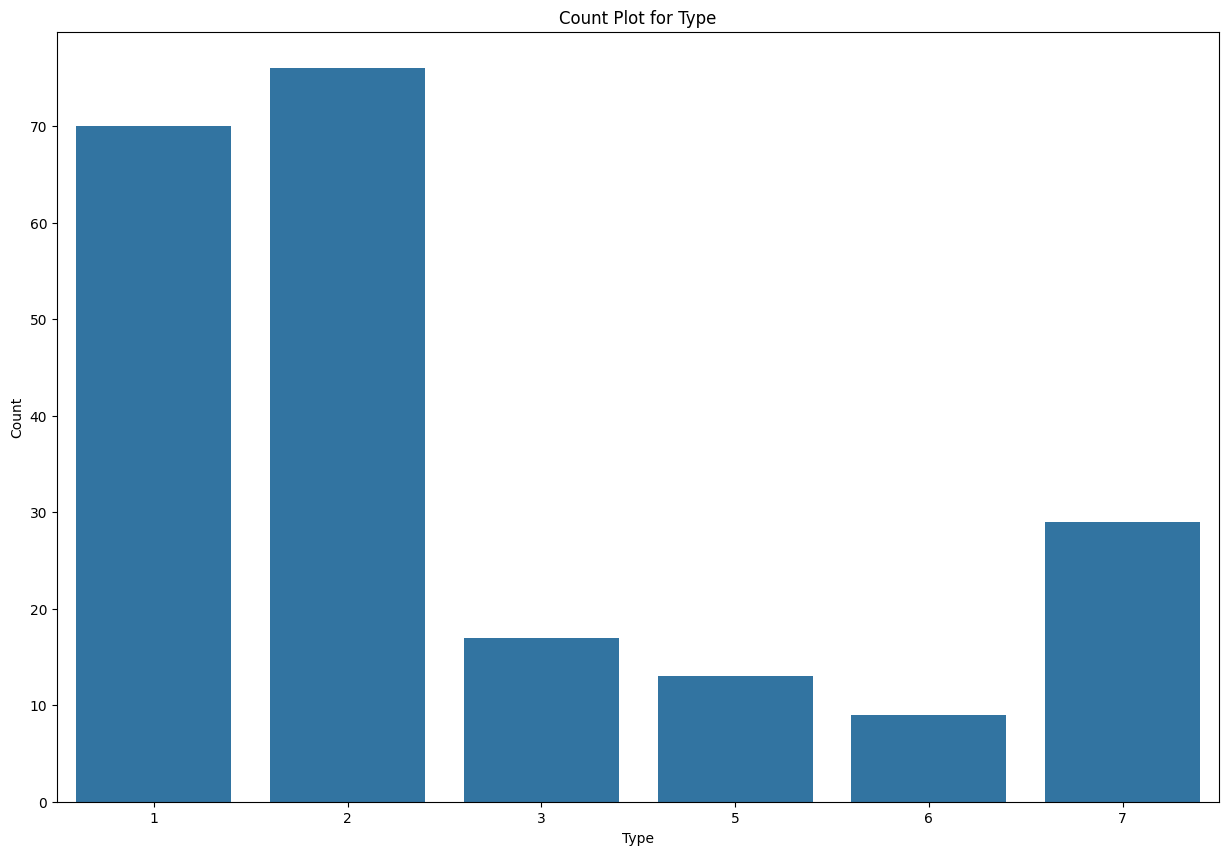

In [12]:
plt.figure(figsize=(15,10))
sns.countplot(
    data=df,
    x="Type"
)

plt.title("Count Plot for Type")
plt.xlabel("Type")
plt.ylabel("Count")
plt.show()

Pie Chart

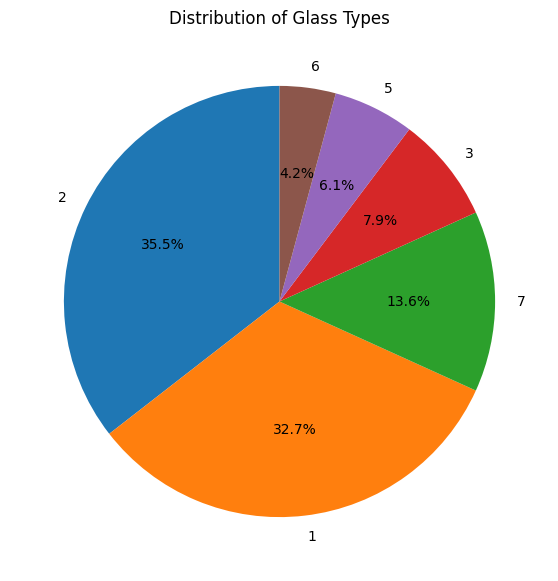

In [13]:
class_counts=df['Type'].value_counts()

plt.figure(figsize=(7,7))
plt.pie(
    class_counts,
    labels=class_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Glass Types')
plt.show()

In [14]:
numerical_features=df.select_dtypes(include=np.number).columns

print("Numerical Features:")
print(numerical_features)

Numerical Features:
Index(['RI', 'Na', 'Mg', 'Al', 'Si', 'K', 'Ca', 'Ba', 'Fe', 'Type'], dtype='object')


Histogram

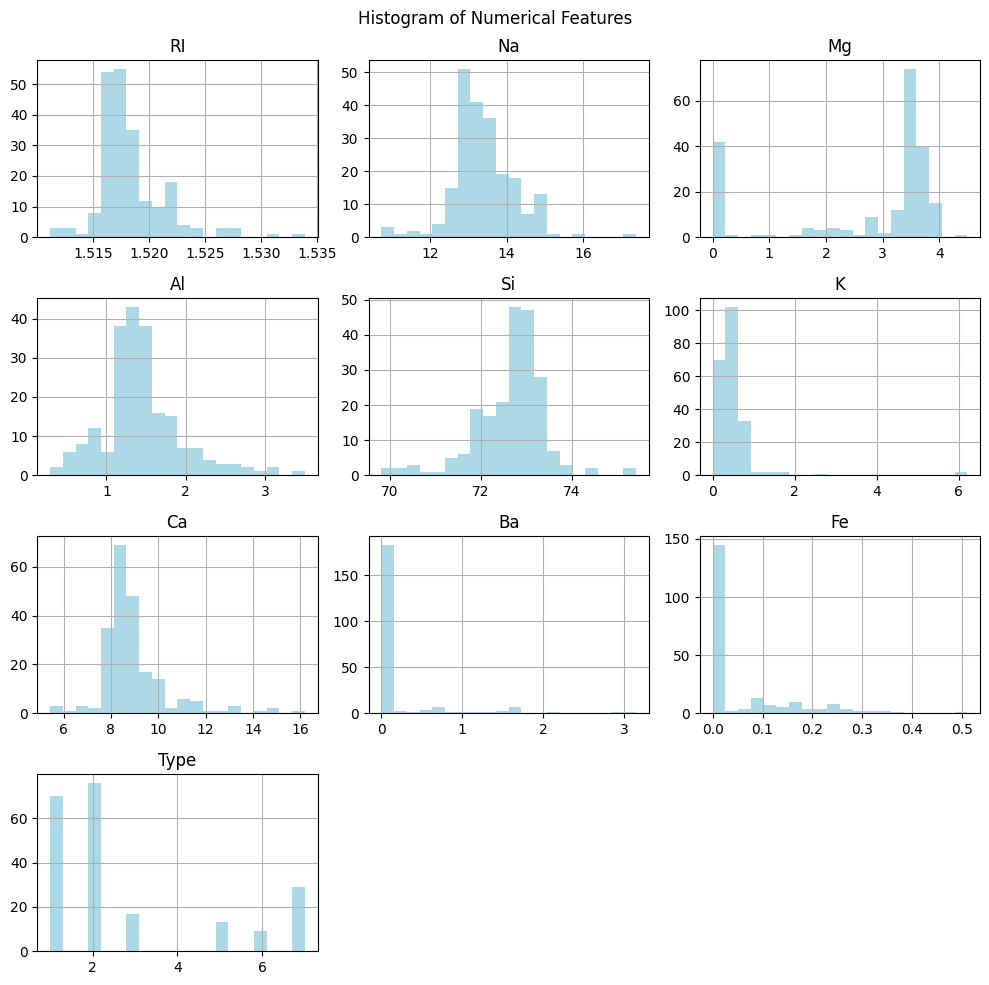

In [15]:
df[numerical_features].hist(figsize=(10,10),bins=20,color='lightblue')
plt.suptitle("Histogram of Numerical Features",fontsize=12)
plt.tight_layout()
plt.show()

Boxplsot


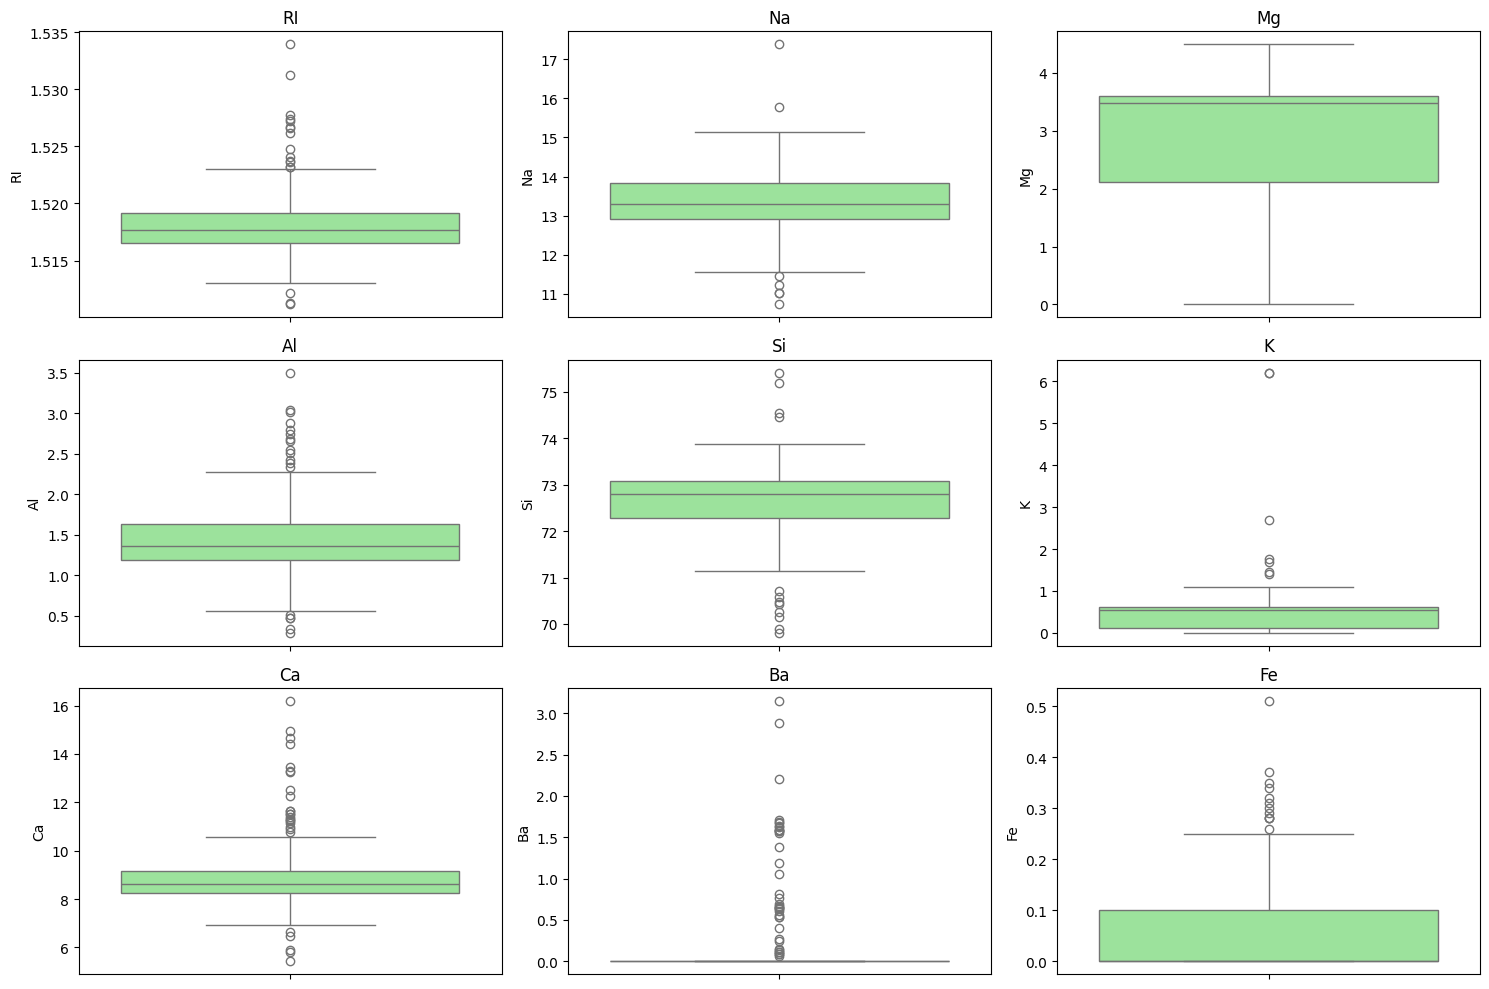

In [16]:
features = df.drop(columns=['Type']).select_dtypes(include=np.number).columns

plt.figure(figsize=(15,10))
for i, column in enumerate(features):
    plt.subplot(3,3,i+1)
    sns.boxplot(df[column],color='lightgreen')
    plt.title(column)

plt.tight_layout()
plt.show()

Histogram with kde function

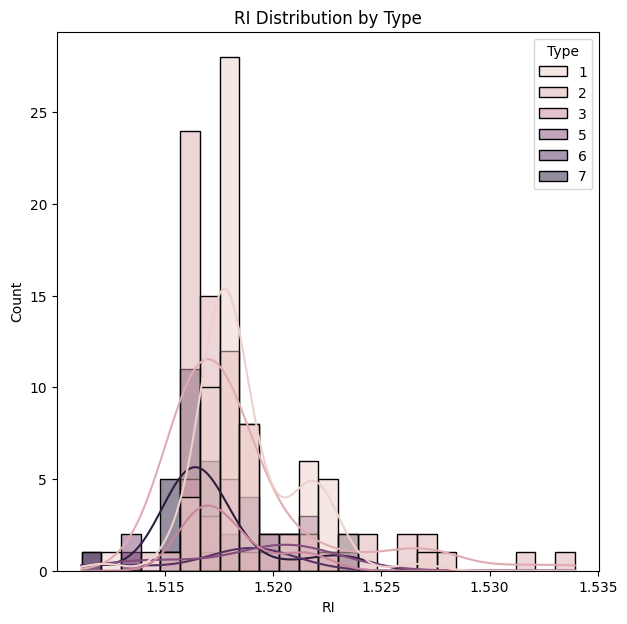

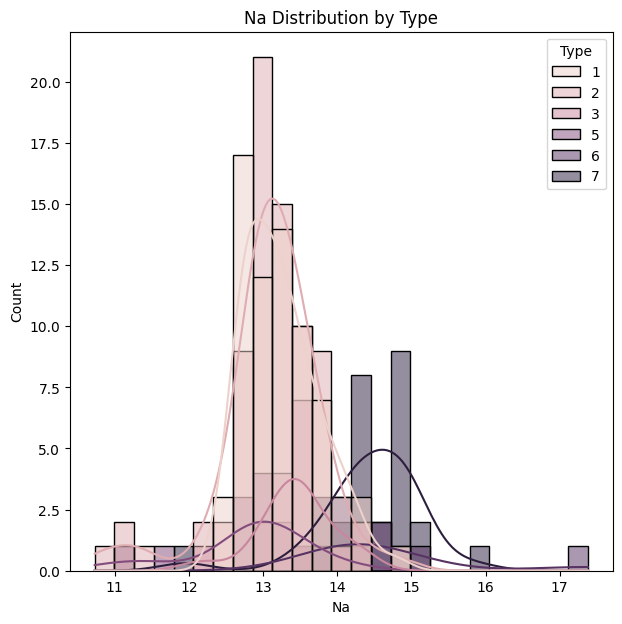

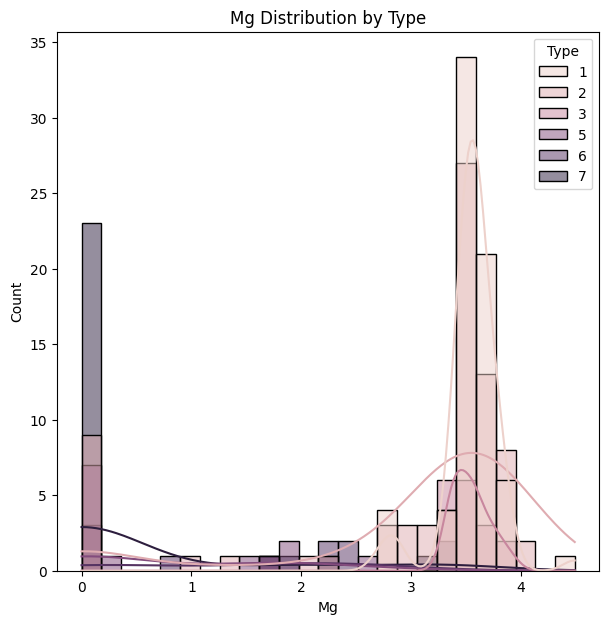

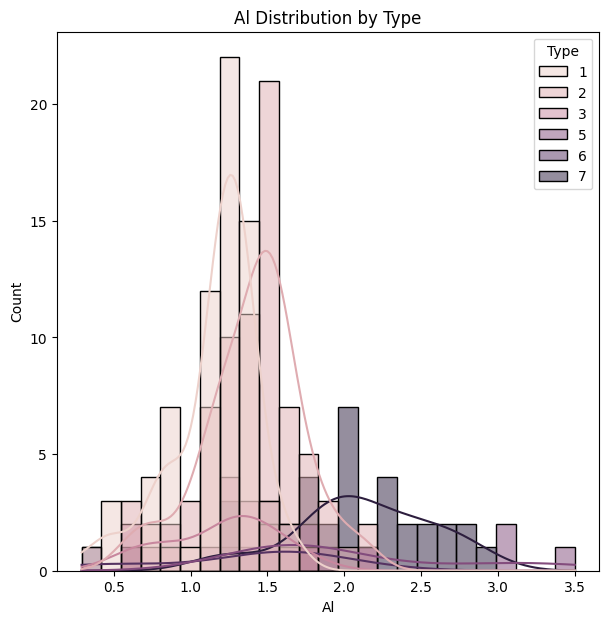

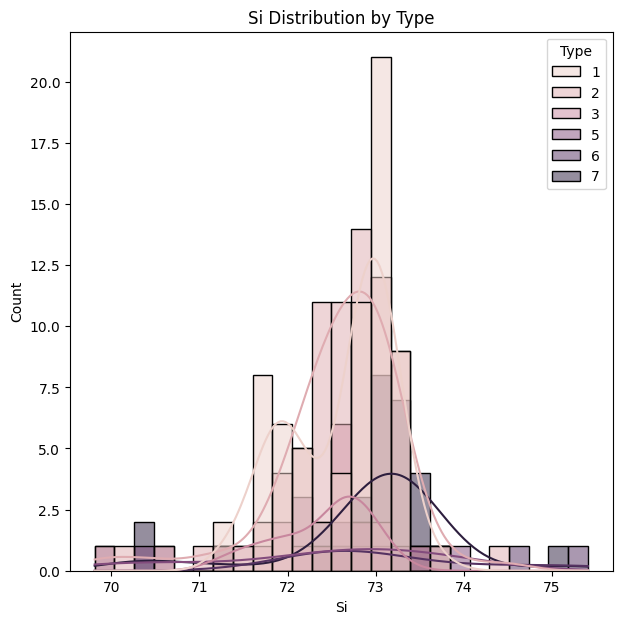

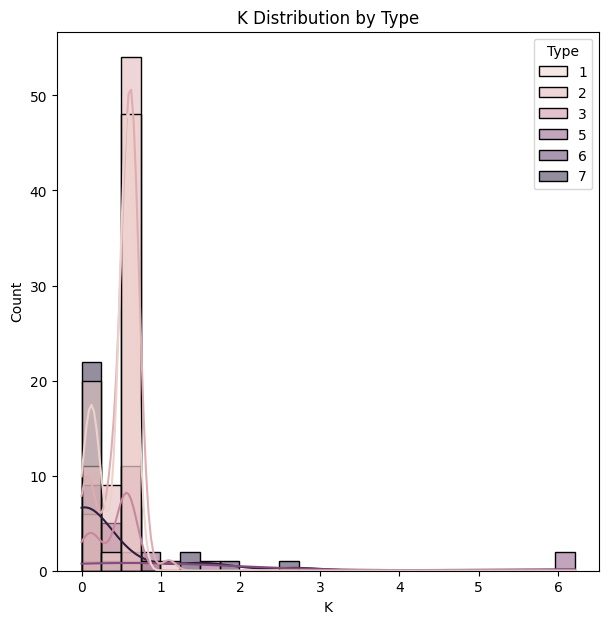

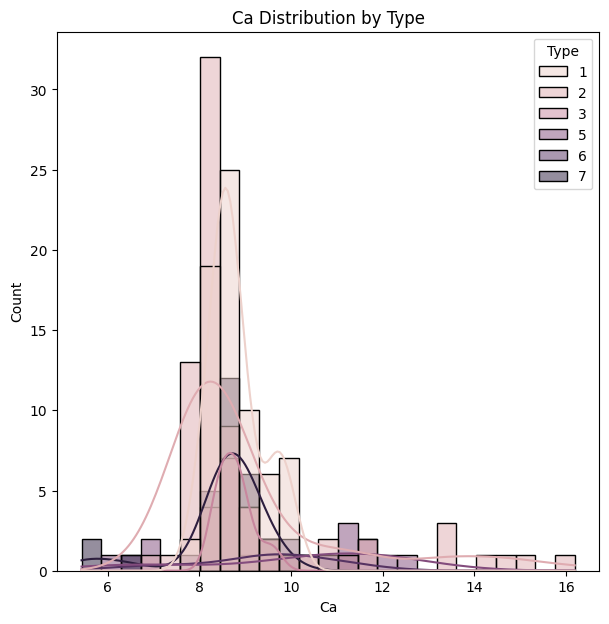

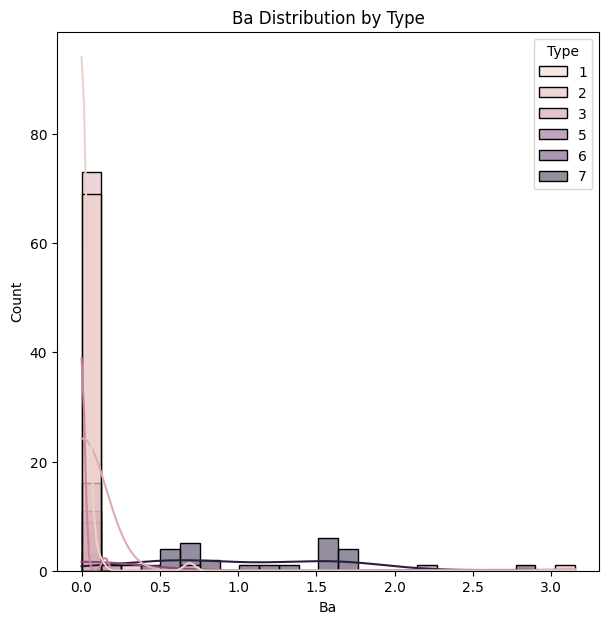

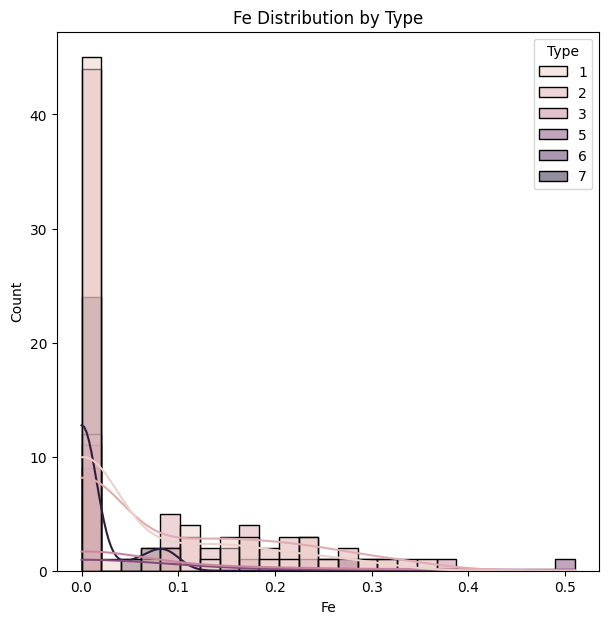

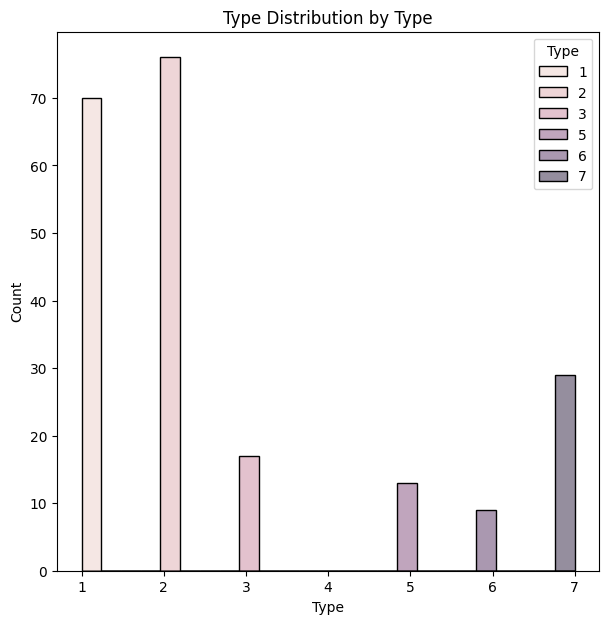

In [17]:
for column in numerical_features:
    plt.figure(figsize=(7,7))
    sns.histplot(
        data=df,
        x=column,
        hue='Type',
        kde=True,
        bins=25
    )
    plt.title(f"{column} Distribution by Type")
    plt.show()

Correlation matrix

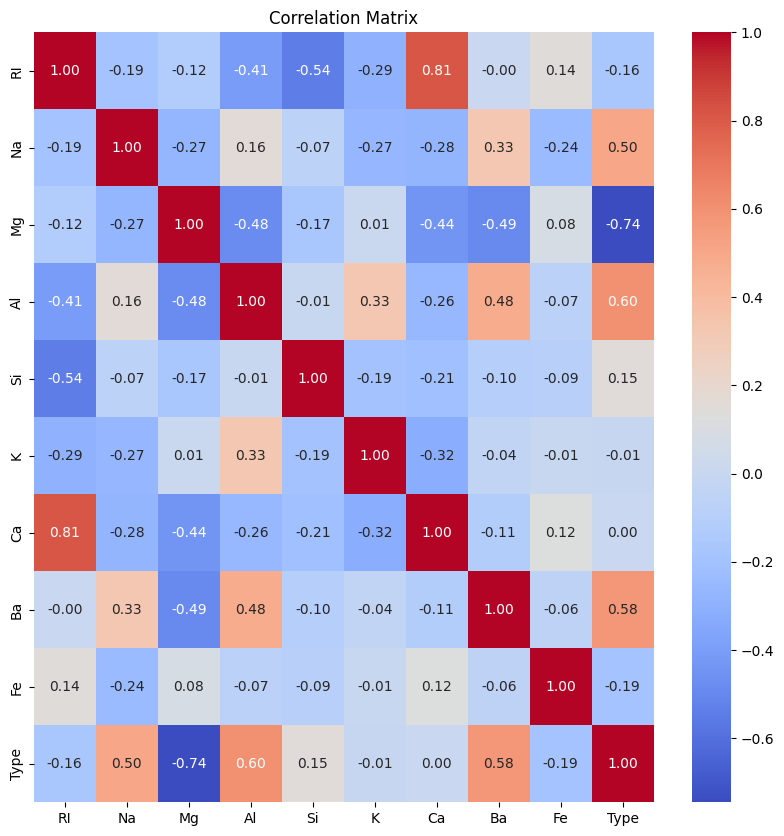

In [18]:
correlation_matrix=df[numerical_features].corr()

plt.figure(figsize=(10,10))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm"
)

plt.title("Correlation Matrix")
plt.show()

Scatter plot

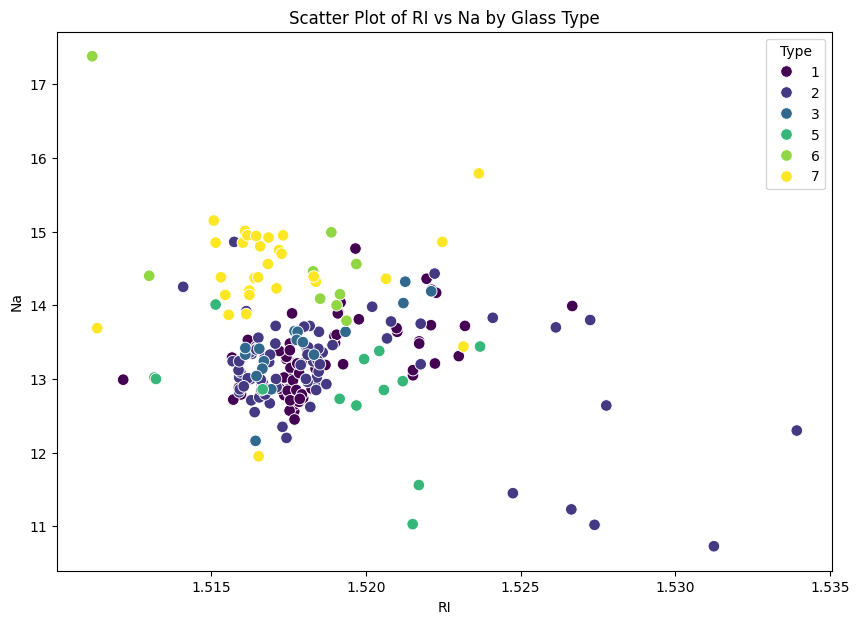

In [37]:
plt.figure(figsize=(10,7))
sns.scatterplot(
    data=df,
    x='RI',
    y='Na',
    palette='viridis',
    hue='Type',
    s=70
)

plt.title("Scatter Plot of RI vs Na by Glass Type")
plt.xlabel("RI")
plt.ylabel("Na")
plt.show()

In [20]:
label_encoder=LabelEncoder()

df["Type_encoded"]=label_encoder.fit_transform(df["Type"])

print(df[["Type","Type_encoded"]].head(10))

   Type  Type_encoded
0     1             0
1     1             0
2     1             0
3     1             0
4     1             0
5     1             0
6     1             0
7     1             0
8     1             0
9     1             0


In [21]:
X=df.drop(["Type", "Type_encoded"],axis=1)
y=df["Type_encoded"]

print("Shape of X:",X.shape)
print("Shape of y:",y.shape)

Shape of X: (214, 9)
Shape of y: (214,)


In [22]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training X_train:",X_train.shape[0])
print("Testing X_test:",X_test.shape[0])

Training X_train: 171
Testing X_test: 43


In [23]:
GaussianNB()

GaussianNB()

In [24]:
gnb = GaussianNB()

gnb.fit(X_train, y_train)

GaussianNB()

In [25]:
y_pred= gnb.predict(X_test)

print("Predicted Labels:")
print(y_pred)

Predicted Labels:
[5 1 0 3 0 0 0 1 0 0 0 0 5 4 0 5 5 0 0 1 0 0 5 0 2 0 1 4 0 0 3 0 0 5 0 0 0
 0 0 2 1 4 4]


In [26]:
comparison=pd.DataFrame({"Actual Labels":y_test.values,"Predicted Labels":y_pred})

print(comparison)

    Actual Labels  Predicted Labels
0               5                 5
1               3                 1
2               1                 0
3               3                 3
4               0                 0
5               0                 0
6               1                 0
7               1                 1
8               0                 0
9               0                 0
10              2                 0
11              0                 0
12              5                 5
13              4                 4
14              1                 0
15              5                 5
16              5                 5
17              0                 0
18              0                 0
19              3                 1
20              0                 0
21              0                 0
22              5                 5
23              1                 0
24              1                 2
25              2                 0
26              1           

In [27]:
accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

Accuracy: 0.5116279069767442
Accuracy (%): 51.162790697674424


In [28]:
precision=precision_score(y_test,y_pred,average='weighted')
print("Precision:",precision)

Precision: 0.47674418604651164


In [29]:
recall = recall_score(y_test, y_pred, average='weighted')
print("Recall:", recall)

Recall: 0.5116279069767442


In [30]:
f1=f1_score(y_test,y_pred,average='weighted')
print("F1 Score:",f1)

F1 Score: 0.45059159526723785


In [31]:
print("====Model performance====")
print("Accuracy:",accuracy)
print("Precision:",precision)
print("Recall:",recall)
print("F1 Score:",f1)

====Model performance====
Accuracy: 0.5116279069767442
Precision: 0.47674418604651164
Recall: 0.5116279069767442
F1 Score: 0.45059159526723785


In [32]:
print("Classification Report:\n")
print(classification_report(y_test,y_pred))

Classification Report:

              precision    recall  f1-score   support

           0       0.50      0.86      0.63        14
           1       0.40      0.13      0.20        15
           2       0.00      0.00      0.00         3
           3       0.50      0.33      0.40         3
           4       0.50      1.00      0.67         2
           5       0.83      0.83      0.83         6

    accuracy                           0.51        43
   macro avg       0.46      0.53      0.46        43
weighted avg       0.48      0.51      0.45        43



In [33]:
cm=confusion_matrix(y_test,y_pred)

print("Confusion Matrix:")
print(cm)

Confusion Matrix:
[[12  1  1  0  0  0]
 [ 9  2  1  0  2  1]
 [ 3  0  0  0  0  0]
 [ 0  2  0  1  0  0]
 [ 0  0  0  0  2  0]
 [ 0  0  0  1  0  5]]


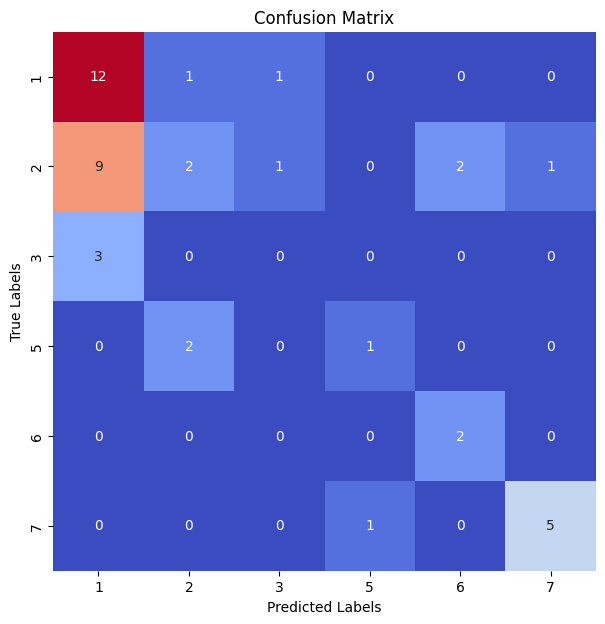

In [34]:
plt.figure(figsize=(7,7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="coolwarm",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    cbar=False
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Labels")
plt.ylabel("True Labels")
plt.show()

In [35]:
from sklearn.metrics import accuracy_score

y_train_pred = gnb.predict(X_train)
y_test_pred = gnb.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print("Training Accuracy:", train_accuracy)
print("Testing Accuracy:", test_accuracy)

Training Accuracy: 0.5555555555555556
Testing Accuracy: 0.5116279069767442
